# 06 · Own pipeline, part 1: YOLO with a P2 head at high resolution

The final pipeline (notebook 07) combines several detectors. This notebook trains its newest member.
Each design choice follows from the earlier results:

| Earlier result | Choice here |
|---|---|
| Small objects are the weakest point of every model (AP_small 0.07–0.10) | a detection output at stride 4 (**P2 head**), as in `fcos_p2`, the only FCOS change that helped |
| 978 of 2,846 val frames are 3840×2160; resized to ~1333 px every object shrinks 2.9× | training also on **2×2 tiles** of frames at least 2000 px wide, so the model sees small objects at the scale of tiled inference |
| Anchor and loss tweaks changed little | a modern detector with strong default augmentation instead of more tweaking |

**YOLO** ("you only look once", Ultralytics, US/UK company) is a one-stage, anchor-free detector:

- **Backbone** CSPDarknet (a CNN, convolutional neural network) and a **PAN neck** (path aggregation
  network: an FPN with an extra bottom-up path) give feature maps at strides 4 (with P2), 8, 16 and 32.
- **Decoupled head:** separate branches for class scores and box distances at every location.
- **Label assignment** by TAL (task-aligned learning): the positives of an object are the locations
  whose predicted box and class score are jointly best, not fixed geometric rules.
- **Losses:** BCE (binary cross-entropy) for classes, CIoU + DFL (distribution focal loss: each box side
  is predicted as a probability distribution over distances) for boxes.
- **Augmentation:** mosaic (four images stitched into one), random scale (±50%) and translation,
  horizontal flip, HSV (hue / saturation / brightness) jitter.

YOLOv8s (11 M parameters) with the official `yolov8s-p2.yaml` definition: every layer gets the COCO
weights of YOLOv8s except the new P2 layers, which start from scratch. Training is limited by time
(1.75 h on a T4 GPU) instead of epochs; Ultralytics adapts the number of epochs and the learning-rate
schedule to that limit. Evaluation uses the same pycocotools code and full val split as every model before.

Albumentations (an augmentation library with Russian authors) is uninstalled in the setup cell:
Ultralytics would otherwise add its blur and colour transforms automatically.

## Setup

In [1]:
# Setup: clone/update the repo on Colab/Kaggle, install requirements, resolve paths, get the data
import os, sys, subprocess
REPO_URL = "https://github.com/anna-kryvulia/ucu-ai-hw-object-detection.git"
BRANCH = "main"   # branch with the code you pushed
if "google.colab" in sys.modules or os.path.exists("/kaggle/working"):
    ROOT = "/content/repo" if "google.colab" in sys.modules else "/kaggle/working/repo"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, ROOT], check=True)
    else:
        subprocess.run(["git", "-C", ROOT, "pull", "-q"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{ROOT}/requirements.txt"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "albumentations"],
                   capture_output=True)   # Ultralytics would apply it automatically; not used here
else:
    ROOT = os.path.abspath("..")
sys.path.insert(0, f"{ROOT}/src")

from hwdet import env
from hwdet.data.download import ensure_data
from hwdet.tracker import Run, status
P = env.setup(seed=42)
ensure_data(P, drive_cache=False)   # Colab: the zip goes to the local disk, not Drive
status(P)                           # which runs / stages are already done

Mounted at /content/drive
platform: colab
    data: /content/data
 outputs: /content/drive/MyDrive/ucu-hw2/outputs
   cache: /content/cache
    repo: /content/repo
  device: cpu
unzipping /content/cache/multiple-object-video-detection-hw-2-ucu-ai-2026.zip -> /content/data


,run_id,stages_done,last_epoch,has_last_ckpt,val_mAP
0,yolo_p2,"train, eval_val, test",15,False,0.201004


In [2]:
# Imports, plot style, W&B login (the key is read from Kaggle / Colab secrets; without it W&B is skipped)
import time
import pandas as pd
import matplotlib.pyplot as plt
import torch

from hwdet.config import load_config
from hwdet.data.detection_dataset import DetectionDataset, build_targets
from hwdet.data.io import frame_table
from hwdet.engine import inference_speed, predict
from hwdet.env import REPO_ROOT
from hwdet.eval.coco_eval import evaluate
from hwdet.submission import make_submission
from hwdet.viz import plot_history, save_fig, set_style
from hwdet.wandb_utils import login_from_secrets
from hwdet.yolo import YoloDetector, export_split, predict_kwargs, train_yolo, write_data_yaml

set_style()
login_from_secrets()
cfg = load_config("yolo_p2")
print("torch", torch.__version__, "| device", env.device())

no WANDB_API_KEY found: runs are tracked locally only
torch 2.14.1+cpu | device cpu


## 1. Data

In [3]:
# Frames and targets with the shared protocol: every 10th training frame, full val, every 5th val frame to monitor
protocol = load_config("_protocol")["split"]
train_frames = frame_table(P.data, "train")
train_frames = train_frames[(train_frames.frame - 1) % protocol["train_frame_step"] == 0]
val_frames = frame_table(P.data, "val")
monitor_frames = val_frames[(val_frames.frame - 1) % protocol["monitor_frame_step"] == 0]
test_frames = frame_table(P.data, "test")
targets = build_targets(P.data, pd.concat([train_frames, val_frames]))
pd.DataFrame({"frames": [len(train_frames), len(val_frames), len(monitor_frames), len(test_frames)],
              "frames ≥ 2000 px wide": [(d.width >= 2000).sum() for d in (train_frames, val_frames, monitor_frames, test_frames)]},
             index=["train (subsampled)", "val", "val monitor", "test"])

,frames,frames ≥ 2000 px wide
train (subsampled),2446,404
val,2846,1560
val monitor,571,313
test,3811,0


## 2. Export in YOLO format

Ultralytics reads one image and one text file per sample (`class cx cy w h`, relative to the image size).
The export uses the same preprocessing as the other detectors: ignored regions are painted with the
mean colour and boxes centred inside them are dropped. Training frames at least 2000 px wide also give
four overlapping tiles (20% overlap); a box cut by a tile border is kept if at least half of it is inside.
Images are saved with a long side of 1280 px, the network input size. The val monitor subset (every 5th
val frame) is exported whole and is only used for Ultralytics' own per-epoch score.

In [4]:
# Write the YOLO dataset to the fast local disk (skipped if already complete)
ex = cfg["export"]
root = P.cache / "yolo"
t0 = time.time()
n_train = export_split(train_frames, targets, P.data, root / "train", long_side=ex["long_side"],
                       tile_grid=ex["tile_grid"], tile_overlap=ex["tile_overlap"],
                       tile_min_width=ex["tile_min_width"], min_visible=ex["min_visible"])
n_val = export_split(monitor_frames, targets, P.data, root / "val", long_side=ex["long_side"])
data_yaml = write_data_yaml(root)
print(f"export: {(time.time() - t0) / 60:.1f} min")
pd.DataFrame({"frames": [len(train_frames), len(monitor_frames)], "images written": [n_train, n_val]},
             index=["train", "val monitor"])

export: 3.9 min


,frames,images written
train,2446,4062
val monitor,571,571


## 3. Training

In [5]:
# Train with a time limit; after a crash the same cell resumes from the last epoch
from ultralytics import settings
settings.update({"wandb": False})          # curves are logged by our own tracker
run = Run("yolo_p2", cfg, P)
if not run.is_done("train"):
    t0 = time.time()
    train_yolo(cfg, run, data_yaml)
    run.mark_done("train")
    print(f"training: {(time.time() - t0) / 3600:.2f} h")
run.history.round(4)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


run 'yolo_p2' at /content/drive/MyDrive/ucu-hw2/outputs/runs/yolo_p2  done: ['train', 'eval_val', 'test']


,epoch,time,box_loss,cls_loss,dfl_loss,val_mAP,val_AP50
0,0,2026-11-09 14:22:01,2.3714,2.4270,2.9232,0.1093,0.2328
1,1,2026-11-09 14:22:01,1.7682,1.5712,1.8726,0.1580,0.3332
2,2,2026-11-09 14:22:01,1.6732,1.3740,1.7246,0.1782,0.3685
3,3,2026-11-09 14:22:01,1.6337,1.2643,1.6647,0.1758,0.3564
4,4,2026-11-09 14:22:01,1.5862,1.1567,1.6128,0.1922,0.3838
5,5,2026-11-09 14:22:01,1.5440,1.0905,1.5777,0.1920,0.3918
6,6,2026-11-09 14:22:01,1.5102,1.0333,1.5429,0.1980,0.4010
7,7,2026-11-09 14:22:01,1.4864,0.9873,1.5238,0.2027,0.4106
8,8,2026-11-09 14:22:01,1.4653,0.9508,1.5016,0.2021,0.4030
9,9,2026-11-09 14:22:01,1.4376,0.9168,1.4738,0.1999,0.4090


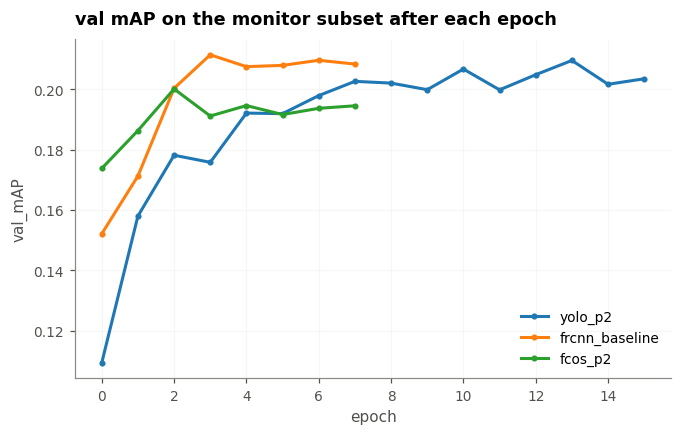

In [6]:
# Val mAP per epoch: YOLO (its own evaluator, monitor subset) next to Faster R-CNN and FCOS-P2 (pycocotools)
hists = {"yolo_p2": run.history}
for r in ("frcnn_baseline", "fcos_p2"):
    f = REPO_ROOT / "results" / "runs" / r / "history.csv"
    if f.exists():
        hists[r] = pd.read_csv(f)
fig, ax = plt.subplots(figsize=(7, 4))
plot_history(hists, "val_mAP", ax=ax)
ax.set_title("val mAP on the monitor subset after each epoch")
save_fig(fig, "yolo_curves", P)
plt.show()

## 4. Evaluation on the full val split, test predictions

The trained model is wrapped so that it takes and returns the same formats as the torchvision detectors,
so prediction, COCO evaluation (with ignored regions) and speed measurement are the same code as before.

In [7]:
# Full val: predictions, COCO metrics, speed; test: predictions and a submission file
det = YoloDetector(run.ckpt("best.pt"), **predict_kwargs(cfg))
dev = env.device()
if not run.is_done("eval_val"):
    val_ds = DetectionDataset(val_frames, P.data, targets)
    preds = predict(det, val_ds, dev, batch_size=8, workers=2, desc="val")
    preds.to_csv(run.pred_path("val"), index=False)
    metrics = evaluate(preds, val_frames, P.data)
    metrics.update(inference_speed(det, val_ds, dev))
    run.log_metrics("val", metrics)
    run.mark_done("eval_val")
if not run.is_done("test"):
    preds = predict(det, DetectionDataset(test_frames, P.data), dev, batch_size=8, workers=2, desc="test")
    preds.to_csv(run.pred_path("test"), index=False)
    make_submission(preds, test_frames, run.dir / "submission.csv")
    run.mark_done("test")
pd.Series(run.metrics["val"]).round(4)

,0
mAP,0.2010
AP50,0.4004
AP75,0.1772
AP_small,0.1015
AP_medium,0.1900
AP_large,0.3355
AR_10,0.2358
AR_100,0.3135
AR_500,0.3168
AR_small,0.2417


In [8]:
# Comparison with all earlier detectors on the same full val split (earlier rows from results/experiments.csv)
cols = ["family", "mAP", "AP50", "AP_small", "AP_medium", "AP_large", "AR_500", "ms_per_img"]
old = pd.read_csv(REPO_ROOT / "results" / "experiments.csv")
old = old[(old["eval"] == "val") & (old["run_id"] != "yolo_p2")].set_index("run_id")
new = pd.DataFrame([{"family": cfg["family"], **run.metrics["val"]}], index=["yolo_p2"])
pd.concat([old, new])[cols].sort_values("mAP", ascending=False).round(3)

,family,mAP,AP50,AP_small,AP_medium,AP_large,AR_500,ms_per_img
frcnn_baseline,two_stage,0.209,0.425,0.091,0.183,0.404,0.411,140.847
frcnn_giou,two_stage,0.206,0.431,0.099,0.193,0.368,0.398,140.446
frcnn_roi_sampling,two_stage,0.205,0.417,0.091,0.185,0.387,0.388,139.780
yolo_p2,pipeline,0.201,0.400,0.102,0.190,0.335,0.317,148.333
fcos_p2,anchor_free,0.199,0.399,0.098,0.184,0.352,0.441,509.047
frcnn_small_anchors,two_stage,0.198,0.416,0.093,0.191,0.347,0.362,153.871
retina_tuned,one_stage,0.194,0.395,0.074,0.181,0.336,0.383,128.584
fcos_ciou,anchor_free,0.190,0.387,0.096,0.173,0.340,0.410,210.995
retina_focal,one_stage,0.189,0.365,0.071,0.172,0.344,0.365,129.272
fcos_baseline,anchor_free,0.189,0.385,0.095,0.174,0.334,0.412,211.719


In [9]:
# Distinct warnings logged in this session (should be empty)
run.finish()
env.warnings_summary(P)

["SyntaxWarning: invalid escape sequence '\\/' [notebookapp.py:191]"]